# Exercise 2 · Image Blending Using OpenCV
The notebook creates two sample PNG files, reads them with OpenCV, and saves the blend beside the originals.

# 1. Create and load the sample images
The samples have the same aspect ratio but different sizes. OpenCV reads images in BGR order (blue, green, red).

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

image_dir = Path("Exercise_2_Images")
image_dir.mkdir(exist_ok=True)

first_path = image_dir / "Original_1.png"
second_path = image_dir / "Original_2.png"
blended_path = image_dir / "Blended.png"


def save_image(path, image):
    if not cv2.imwrite(str(path), image):
        raise OSError(f"Could not save {path}")


# Create two sample PNGs. OpenCV color tuples use BGR order.
sample_one = np.full((320, 480, 3), (60, 38, 27), dtype=np.uint8)
cv2.circle(sample_one, (185, 160), 105, (76, 195, 254), -1, cv2.LINE_AA)

sample_two = np.full((240, 360, 3), (58, 28, 50), dtype=np.uint8)
cv2.rectangle(sample_two, (145, 52), (302, 186), (205, 180, 38), -1, cv2.LINE_AA)

save_image(first_path, sample_one)
save_image(second_path, sample_two)

image_one = cv2.imread(str(first_path))
image_two = cv2.imread(str(second_path))

if image_one is None or image_two is None:
    raise OSError("Could not read one or both sample images.")

print(f"Original 1: {image_one.shape[1]} × {image_one.shape[0]} pixels")
print(f"Original 2: {image_two.shape[1]} × {image_two.shape[0]} pixels")

Original 1: 480 × 320 pixels
Original 2: 360 × 240 pixels


Each blended pixel combines 55% of the day image and 45% of the night image.
OpenCV loads the source PNGs in BGR order, so the display converts them to RGB.
The two source PNGs and the saved blend are the inputs for Exercise 3.

# 2. Match the dimensions and blend
OpenCV blends corresponding pixels, so both arrays must have the same dimensions. Resize the second image in memory to match the first. The blend uses 60% of the first image and 40% of the second, with a brightness offset of zero.

In [2]:
height, width = image_one.shape[:2]

image_two_for_blend = image_two
if image_two.shape[:2] != (height, width):
    image_two_for_blend = cv2.resize(image_two, (width, height))

alpha = 0.6
beta = 1 - alpha
blended = cv2.addWeighted(image_one, alpha, image_two_for_blend, beta, 0)

save_image(blended_path, blended)
print(f"Saved all three PNG files in {image_dir.resolve()}")

Saved all three PNG files in /Users/e31977600/Excercises/Exercise_2_Images


# 3. Compare the originals and the blended image
Matplotlib expects RGB, so convert each image from BGR before displaying it. The middle panel shows the original second image at its saved resolution.

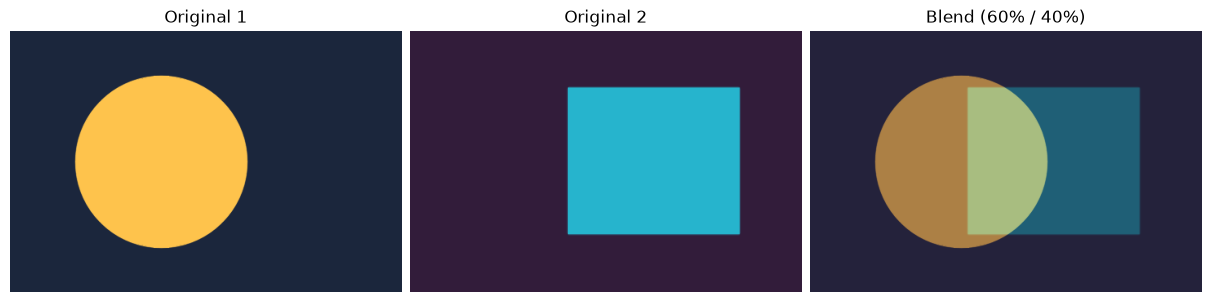

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")

for ax, title, image in zip(
    axes,
    ["Original 1", "Original 2", f"Blend ({alpha:.0%} / {beta:.0%})"],
    [image_one, image_two, blended],
):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.set_axis_off()

plt.show()